In [1]:
!pip install optuna
!pip install MLstatkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 17.5 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np
from MLstatkit import Delong_test
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score, ParameterGrid, StratifiedKFold
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, brier_score_loss, roc_curve, accuracy_score, recall_score, confusion_matrix, f1_score, classification_report, brier_score_loss
from sklearn.utils import resample
import xgboost as xgb
import shap
import optuna
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.metrics import AUC
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop

# 1. Import dataset y filtrado

In [ ]:
df_form1 = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/NSCISC-public-data-2021/f1_public_2021.csv', low_memory=False)
df_form2 = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/NSCISC-public-data-2021/f2_public_2021.csv', low_memory=False)

In [ ]:
df_form1.shape, df_form2.shape

((35675, 658), (131217, 325))

In [ ]:
# filtramos Date of First System Admission entre 2000 y 2019
# nos quedamos con todos los pacientes desde enero 2000 hasta diciembre 2019 aunque el paper
# original utilice solo hasta mayo 2019 porque solo existen datos de año, no de mes

# Etiología traumática válida (no NaN) -> "primary diagnosis of SCI admitted to an SCI model system center"

df_form1_filtered = df_form1[(df_form1['AAdmDt'] >= 2000) & (df_form1['AAdmDt'] <= 2019) & (df_form1["ATrmEtio"].notna())]

df_form1_filtered.shape

(14395, 658)

In [ ]:
# form2 tiene un formulario por cada paciente cada x años (hay varios form2 por cada paciente)
# en este caso, nos interesan solo los formularios para ver el estado de los pacientes tras 1 año

df_form2_1year = df_form2[df_form2['BYear'] == 1]


In [ ]:
# antes de unir los dos df en uno, comprobamos que no hay columnas con el mismo nombre

set(df_form1.columns) & set(df_form2.columns)

{'UniID'}

In [ ]:
# unimos los df en uno
df_filtered_1 = df_form1_filtered.merge(df_form2_1year, how='left', on='UniID')

# nos quedamos con los que no tienen la variable de salida 'no válida' o NaN
# = 9 -> unknown
df_filtered_1 = df_filtered_1[df_filtered_1['BWlk150'] != 9.0]
df_filtered_1 = df_filtered_1.dropna(subset=['BWlk150'])

df_filtered_1 = df_filtered_1.reset_index(drop=True)

In [ ]:
df_filtered_1.head()

,ANSysAdM,ARbAdDtM,ASDDAc2R,ASDDDurR,AI2ADays,AI2RhADa,AHDaSyAc,AHDaSyRb,ASex,APResInj,...,BMotLvLf,BPrNuFRt,BPrNuFLf,BNurLvl,BAnalSns,BVolSphn,BASAImp,BNImpCat,BIntvDt,BAnExDt
0,9,1,0,0,14,30,16,32,2,1,...,X99,X99,X99,X99,9.0,9.0,U,9.0,2005.0,2005.0
1,9,1,0,0,10,22,12,35,1,1,...,X99,X99,X99,X99,9.0,9.0,U,9.0,2004.0,2004.0
2,9,1,0,0,7,42,35,29,1,1,...,X99,X99,X99,X99,9.0,9.0,U,9.0,2004.0,NaN
3,9,1,0,0,9,13,4,53,1,1,...,X99,X99,X99,X99,9.0,9.0,U,9.0,2005.0,NaN
4,9,1,0,0,27,52,25,25,1,1,...,X99,X99,X99,X99,9.0,9.0,U,9.0,2003.0,NaN


In [ ]:
# "excluded due to unavailability of light touch and pin prick testing"
# variables predictoras se obtuvieron "during the acute rehabilitation period", nos quedamos con los sufijos RR (right) o RL (left)
# según el data dictionary, hay 3 tipos de columnas: each dermatome, subtotal right and left, total

# LT = Light Touch (tacto ligero)
# PP = Pin Prick (pinchazo)
# RR = Rehab Rehabilitation Admission (al ingreso en rehabilitación)


# CÓDIGOS:
# each dermatome: 8 Not Testable, unable to test; infants; cast; amputee.   9 Unknown, Not Done, No System rehab admission (for Rehab admit position only)
# subtotal: 88 Not Testable, unable to test; infants; cast; amputee.   99 Unknown, Not Done, No System rehab admission (for Rehab admit position only)
# total: 888 Not Testable, unable to test; infants; cast; amputee.   999 Unknown, Not Done, No System rehab admission (for Rehab admit position only)



cols_dermatome = [
    "AASAC5RR", "AASAC6RR", "AASAC7RR", "AASAC8RR",
    "AASAT1RR", "AASAL2RR", "AASAL3RR", "AASAL4RR", "AASAL5RR", "AASAS1RR", "AASAStRR",
    "AASAC5RL", "AASAC6RL", "AASAC7RL", "AASAC8RL",
    "AASAT1RL", "AASAL2RL", "AASAL3RL", "AASAL4RL", "AASAL5RL", "AASAS1RL", "AASAStRL",
    "ALTC2RR", "ALTC3RR", "ALTC4RR", "ALTC5RR", "ALTC6RR", "ALTC7RR", "ALTC8RR",
    "ALTT1RR", "ALTT2RR", "ALTT3RR", "ALTT4RR", "ALTT5RR", "ALTT6RR", "ALTT7RR", "ALTT8RR",
    "ALTT9RR", "ALTT10RR", "ALTT11RR", "ALTT12RR",
    "ALTL1RR", "ALTL2RR", "ALTL3RR", "ALTL4RR", "ALTL5RR",
    "ALTS1RR", "ALTS2RR", "ALTS3RR", "ALTS45RR",
    "ALTC2LR", "ALTC3LR", "ALTC4LR", "ALTC5LR", "ALTC6LR", "ALTC7LR", "ALTC8LR",
    "ALTT1LR", "ALTT2LR", "ALTT3LR", "ALTT4LR", "ALTT5LR", "ALTT6LR", "ALTT7LR", "ALTT8LR",
    "ALTT9LR", "ALTT10LR", "ALTT11LR", "ALTT12LR",
    "ALTL1LR", "ALTL2LR", "ALTL3LR", "ALTL4LR", "ALTL5LR",
    "ALTS1LR", "ALTS2LR", "ALTS3LR", "ALTS45LR",
    "APPC2RR", "APPC3RR", "APPC4RR", "APPC5RR", "APPC6RR", "APPC7RR", "APPC8RR",
    "APPT1RR", "APPT2RR", "APPT3RR", "APPT4RR", "APPT5RR", "APPT6RR", "APPT7RR", "APPT8RR",
    "APPT9RR", "APPT10RR", "APPT11RR", "APPT12RR",
    "APPL1RR", "APPL2RR", "APPL3RR", "APPL4RR", "APPL5RR",
    "APPS1RR", "APPS2RR", "APPS3RR", "APPS45RR",
    "APPC2LR", "APPC3LR", "APPC4LR", "APPC5LR", "APPC6LR", "APPC7LR", "APPC8LR",
    "APPT1LR", "APPT2LR", "APPT3LR", "APPT4LR", "APPT5LR", "APPT6LR", "APPT7LR", "APPT8LR",
    "APPT9LR", "APPT10LR", "APPT11LR", "APPT12LR",
    "APPL1LR", "APPL2LR", "APPL3LR", "APPL4LR", "APPL5LR",
    "APPS1LR", "APPS2LR", "APPS3LR", "APPS45LR"
]

cols_subtotal = ['ALTSubRR', 'ALTSubLR', "APPSubRR", "APPSubLR"]

cols_total = ["AASATotR", "ALTTotRh"]


# nos quitamos filas que tengan ALGÚN valor NO VÁLIDO en dichas columnas
df_filtered_2 = df_filtered_1[~df_filtered_1[cols_dermatome].isin([9, 8]).any(axis=1)]
df_filtered_2 = df_filtered_2[~df_filtered_2[cols_subtotal].isin([99, 88]).any(axis=1)]
df_filtered_2 = df_filtered_2[~df_filtered_2[cols_total].isin([999, 888]).any(axis=1)]


# quitamos también valores nan
df_filtered_2 = df_filtered_2.dropna(axis=0, subset=cols_dermatome + cols_subtotal + cols_total)


print(f"{len(df_filtered_2)} filas tienen examen sensorial/motor válido")


4057 filas tienen examen sensorial/motor válido


### Comprobación estadísticas demográficas

Como tenemos un número de pacientes diferente que el estudio original (4057 vs. 4523) , vamos a comprobar las estadísticas demográficas de nuestro conjunto de datos y compararlas con las establecidas por el estudio original. Si vemos que estas son razonablemente equivalentes, aceptaremos el nuevo conjunto de datos como el original.

NOTA: En el paper viene una tabla con todas las estadísticas, yo he calculado las estadísticas que vienen ESCRITAS en el paper.


In [ ]:
# porcentaje sexo hombres (1) original = 79.7% frente a 79.6% de nuestros datos

df_filtered_2['ASex'].value_counts() / len(df_filtered_2)

,count
ASex,
1,0.796401
2,0.202859
3,0.000739


In [ ]:
# porcentaje raza caucásica (1) original = 70.7% frente a 69.6% de nuestros datos

df_filtered_2['ARace'].value_counts() / len(df_filtered_2)


,count
ARace,
1,0.696081
2,0.223564
5,0.038452
4,0.020458
9,0.009613
3,0.008134
7,0.003697


In [ ]:
# los años de las personas están agrupados como string cuando se trata de niños menores de 15 años,
# el paper original establece que, quitando estos, la edad mediana son 41 años
# nuestros datos tienen como edad mediana 40 años

age_col_float = pd.to_numeric(df_filtered_2['AInjAge'], errors='coerce').dropna()

age_col_float.median()

40.0

In [ ]:
# paper: The most common etiology of injury was vehicular accident (39.6%)
# en nuestro análisis vehicular accident es también la categoría más común, con un 38.5%

# agrupamos los códigos según sus categorías
vehicular_codes = [1, 2, 3, 4, 5, 6, 7, 8, 9]
violence_codes = [10,11,12,15]
sports_codes = [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 70, 71, 72, 73, 74, 75, 76, 77, 78]
falls_codes = [30,31]
pedestrian_code = [40]
medical_code = [50]

groups = {
    "vehicular": vehicular_codes,
    "violence": violence_codes,
    "sports": sports_codes,
    "falls": falls_codes,
    "pedestrian": pedestrian_code,
    "medical": medical_code
}

accident_etiology = pd.Series({
    name: df_filtered_2['ATrmEtio'][df_filtered_2['ATrmEtio'].isin(codes)].count()
    for name, codes in groups.items()
})

accident_etiology / len(df_filtered_2)

,0
vehicular,0.385260
violence,0.142716
sports,0.091940
falls,0.320187
pedestrian,0.008134
medical,0.043628


In [ ]:
# the most common neurologic level of injury was cervical (60.8%)

# esta puede ser una de las categorías que más difiere del dataset original (49.5% vs 60.8%)

neurologic_injury = df_filtered_2['ASLRhbRt'].str[0].value_counts()

neurologic_injury / len(df_filtered_2)

,count
ASLRhbRt,
C,0.495686
T,0.384274
L,0.073946
X,0.036973
S,0.009120


Dado este análisis, tomaremos como suficientemnete parecido el dataset que tenemos actualmente comparado con el que se utilizó en el estudio original.

In [ ]:
df = df_filtered_2

outcome = 'BWlk150'

asia_ingreso = "AASAImAd" -- ASIA acute medical care (for day-1 admissions only)

asia_rehab = 'AASAImRb -- at admission to rehab (for all patients admitted to rehab)

In [ ]:
print(f'Tenemos {len(df)} pacientes, de los cuales {(df['BWlk150'] == 1).sum()} ambulan y {(df['BWlk150'] == 0).sum()} no')

Tenemos 4057 pacientes, de los cuales 1724 ambulan y 2333 no


### Selección de variables (columnas)

Arreglar el dataset para quedarnos con las columnas que queremos y que se llamen de forma más identificativa.

In [ ]:
# Injury Etiology Category

vehicular_codes = [1, 2, 3, 4, 5, 6, 7, 8, 9]
violence_codes = [10,11,12,15]
sports_codes = [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 70, 71, 72, 73, 74, 75, 76, 77, 78]
falls_codes = [30,31]
pedestrian_code = [40]
medical_code = [50]

etiology_map = {}
for category, codes in [
    ("vehicular", vehicular_codes),
    ("violence", violence_codes),
    ("sports", sports_codes),
    ("falls", falls_codes),
    ("pedestrian", pedestrian_code),
    ("medical", medical_code)
]:
    for code in codes:
        etiology_map[code] = category

df['ATrmEtio'] = df['ATrmEtio'].map(etiology_map).fillna('Other')

# bmi, pasamos peso de libras a kg y altura de pulgadas a m

df['bmi'] = np.where(
    (df['AHghtRhb'] != 999) & (df['AWghtRhb'] != 999),
    (df['AWghtRhb'] / 2.205) / ((df['AHghtRhb'] * 2.54 / 100) ** 2),
    np.nan
)


# lo hago antes porque si no me da error de que no puede operar con NaN
df['bmi'] = df['bmi'].fillna(
    df.groupby(['ASex', 'AInjAge'])['bmi'].transform('median')
)

In [ ]:
# todas columnas del form I, menos las de at 1-year

cols_experiment = ['ASex', 'ARace', 'AHispnic', 'AMarStIj', 'AEducLvl', 'APrLvlSt', 'ATrmEtio', 'AVertInj', 'AAsscInj',
                   'ASpinSrg', 'AUMVAdm', 'ANurLvlR', 'AVoSphRb', 'AAnSnRhb', 'AASAImRb', 'ANCatRhb', 'AAnxiety', 'ADepress',
                   'ADiabete', 'AHypTen', 'AHypLip', 'AArthr', 'AAlcNbDr', 'AInjAge', 'bmi', 'AHDaSyAc', 'AI2RhADa',
                   'AASAL2RL', 'AASAL3RL', 'AASAL4RL', 'AASAL5RL', 'AASAS1RL', 'AASAL2RR', 'AASAL3RR', 'AASAL4RR', 'AASAL5RR', 'AASAS1RR',
                   'ALTL1LR', 'ALTL2LR', 'ALTL3LR', 'ALTL4LR', 'ALTL5LR', 'ALTS1LR', 'ALTS2LR', 'ALTS3LR', 'ALTS45LR',
                   'ALTL1RR', 'ALTL2RR', 'ALTL3RR', 'ALTL4RR', 'ALTL5RR', 'ALTS1RR', 'ALTS2RR', 'ALTS3RR', 'ALTS45RR',
                   'APPL1LR', 'APPL2LR', 'APPL3LR', 'APPL4LR', 'APPL5LR', 'APPS1LR', 'APPS2LR', 'APPS3LR', 'APPS45LR',
                   'APPL1RR', 'APPL2RR', 'APPL3RR', 'APPL4RR', 'APPL5RR', 'APPS1RR', 'APPS2RR', 'APPS3RR', 'APPS45RR',
                   'BWlk150', 'BWlkBlck', 'BWlkStps', 'BASAImp'

                   ]

In [ ]:
variables = [
    # --- Categorical variables ---
    "Sex",
    "Race",
    "Hispanic",
    "Marital Status",
    "Education",
    "Employment Status",
    "Injury Etiology Category",
    "Vertebral Injury",
    "Associated Injury",
    "Spinal Surgery",
    "Mechanical Ventilation",
    "Neuro Level",
    "Voluntary Anal Contraction",
    "Deep Anal Pressure",
    "ASIA at Rehab",
    "Neuro Impairment",
    "Anxiety",
    "Depression",
    "Diabetes",
    "Hypertension",
    "Hyperlipidemia",
    "Arthritis",
    "Alcohol: # drinks per day",

    # --- Continuous variables ---
    "Age at Injury",
    "BMI",
    "LOS Acute Care",
    "Injury to Rehab Admission",

    # --- ASIA Sub-Tests ---
    # Motor Score
    "Motor Score Left L2",
    "Motor Score Left L3",
    "Motor Score Left L4",
    "Motor Score Left L5",
    "Motor Score Left S1",
    "Motor Score Right L2",
    "Motor Score Right L3",
    "Motor Score Right L4",
    "Motor Score Right L5",
    "Motor Score Right S1",

    # Sensory: LT
    "Sensory LT Left L1",
    "Sensory LT Left L2",
    "Sensory LT Left L3",
    "Sensory LT Left L4",
    "Sensory LT Left L5",
    "Sensory LT Left S1",
    "Sensory LT Left S2",
    "Sensory LT Left S3",
    "Sensory LT Left S4-5",
    "Sensory LT Right L1",
    "Sensory LT Right L2",
    "Sensory LT Right L3",
    "Sensory LT Right L4",
    "Sensory LT Right L5",
    "Sensory LT Right S1",
    "Sensory LT Right S2",
    "Sensory LT Right S3",
    "Sensory LT Right S4-5",

    # Sensory: Pin Prick
    "Sensory PP Left L1",
    "Sensory PP Left L2",
    "Sensory PP Left L3",
    "Sensory PP Left L4",
    "Sensory PP Left L5",
    "Sensory PP Left S1",
    "Sensory PP Left S2",
    "Sensory PP Left S3",
    "Sensory PP Left S4-5",
    "Sensory PP Right L1",
    "Sensory PP Right L2",
    "Sensory PP Right L3",
    "Sensory PP Right L4",
    "Sensory PP Right L5",
    "Sensory PP Right S1",
    "Sensory PP Right S2",
    "Sensory PP Right S3",
    "Sensory PP Right S4-5",

    # endpoint
    "Walk 150 ft at 1-year",
    "Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    "ASIA Score at 1-year"
]


In [ ]:
df_final = df[cols_experiment]
df_final.columns = variables

### Convertir a NaN valores no válidos

In [ ]:
# 7 = declined/doesn't know 9=unknown
df_final.loc[(df_final['Sex'] == 9), 'Sex'] = np.nan
df_final.loc[(df_final['Race'] == 7)|(df_final['Race'] == 9), 'Race'] = np.nan
df_final.loc[(df_final['Hispanic'] == 7)|(df_final['Hispanic'] == 9), 'Hispanic'] = np.nan
df_final.loc[(df_final['Marital Status'] == 9), 'Marital Status'] = np.nan
df_final.loc[(df_final['Education'] == 9), 'Education'] = np.nan
df_final.loc[(df_final['Employment Status'] == 99), 'Employment Status'] = np.nan
df_final.loc[(df_final["Injury Etiology Category"] == 99), "Injury Etiology Category"] = np.nan
df_final.loc[(df_final['Vertebral Injury'] == 9), 'Vertebral Injury'] = np.nan
df_final.loc[(df_final['Associated Injury'] == 9), 'Associated Injury'] = np.nan
df_final.loc[(df_final["Spinal Surgery"] == 9), "Spinal Surgery"] = np.nan
df_final.loc[(df_final["Mechanical Ventilation"] == 9), "Mechanical Ventilation"] = np.nan
df_final.loc[(df_final["Neuro Level"] == 'X99')|(df_final["Neuro Level"] == '703')|(df_final["Neuro Level"] == "304")|(df_final["Neuro Level"] == "X00"), "Neuro Level"] = np.nan
df_final.loc[(df_final['Voluntary Anal Contraction'] == 8)|(df_final['Voluntary Anal Contraction'] == 9), 'Voluntary Anal Contraction'] = np.nan
df_final.loc[(df_final['Deep Anal Pressure'] == 8)|(df_final['Deep Anal Pressure'] == 9), 'Deep Anal Pressure'] = np.nan
df_final.loc[(df_final['ASIA at Rehab'] == 'U'), 'ASIA at Rehab'] = np.nan
df_final.loc[(df_final['Neuro Impairment'] == 9), 'Neuro Impairment'] = np.nan
df_final.loc[(df_final['Anxiety'] == 7)|(df_final['Anxiety'] == 9), 'Anxiety'] = np.nan
df_final.loc[(df_final['Depression'] == 7)|(df_final['Depression'] == 9), 'Depression'] = np.nan
df_final.loc[(df_final['Diabetes'] == 7)|(df_final['Diabetes'] == 9), 'Diabetes'] = np.nan
df_final.loc[(df_final['Hypertension'] == 7)|(df_final['Hypertension'] == 9), 'Hypertension'] = np.nan
df_final.loc[(df_final['Hyperlipidemia'] == 7)|(df_final['Hyperlipidemia'] == 9), 'Hyperlipidemia'] = np.nan
df_final.loc[(df_final['Arthritis'] == 7)|(df_final['Arthritis'] == 9), 'Arthritis'] = np.nan
df_final.loc[(df_final["Alcohol: # drinks per day"] == 7)|(df_final["Alcohol: # drinks per day"] == 9), "Alcohol: # drinks per day"] = np.nan

df_final.loc[(df_final['Age at Injury'] == 999), 'Age at Injury'] = np.nan

mapeo_edad = {
    '13-14y': (13+14)/2.0,
    '6-12y': (6+12)/2.0,
    '88+y': 90
}

df['Age at Injury'] = df_final['Age at Injury'].replace(mapeo_edad).astype('float')
df_final['Age at Injury'] = df_final['Age at Injury'].replace(mapeo_edad).astype('float')

# en el paper aclaran que no hay ningún paciente con LOS Acute Care > 242
df_final.loc[df_final['LOS Acute Care'] > 242, 'LOS Acute Care'] = np.nan
df_final.loc[(df_final['Injury to Rehab Admission'] == 888), 'Injury to Rehab Admission'] = np.nan

# Motor score, sensory light touch y sensory pin prick ya nos lo hemos quitado

df_final.loc[(df_final["Walk One Block at 1-year"] == 9), "Walk One Block at 1-year"] = np.nan
df_final.loc[(df_final["Walk Flight of Stairs at 1-year"] == 9), "Walk Flight of Stairs at 1-year"] = np.nan

df_final.loc[(df_final["ASIA Score at 1-year"] == 'U'), "ASIA Score at 1-year"] = np.nan



/tmp/ipykernel_363/1547525344.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Age at Injury'] = df_final['Age at Injury'].replace(mapeo_edad).astype('float')


### Conversión de tipos

Hasta ahora, el desarrollo ha sido exactamente igual al del cuadernillo 'Recreación-experimento-TFG.ipynb'. A partir de ahora, se trabajan con los cambios/mejoras propuestos por los profesionales con los que hemos trabajado.

 Conversión de tipos de variables propuestos por los profesionales (detallados en el documento *Optimización de Modelos Predictivos y Calidad de datos.docx*)


#### Variables ordinales

In [ ]:
# Neuro Level
map_neurolevel = {
   # Cervicales
   'C01': 1, 'C02': 2, 'C03': 3, 'C04': 4,
   'C05': 5, 'C06': 6, 'C07': 7, 'C08': 8,
   # Torácicas
   'T01': 9, 'T02': 10, 'T03': 11, 'T04': 12,
   'T05': 13, 'T06': 14, 'T07': 15, 'T08': 16,
   'T09': 17, 'T10': 18, 'T11': 19, 'T12': 20,
   # Lumbares
   'L01': 21, 'L02': 22, 'L03': 23, 'L04': 24, 'L05': 25,
   # Sacras
   'S01': 26, 'S02': 27, 'S03': 28, 'S04': 28, 'S05': 28
}


df_final['Neuro Level'] = df_final['Neuro Level'].map(map_neurolevel)


# Asia at Rehab, ASIA Score at 1-year
map_asia = {
   'A': 1,
   'B': 2,
   'C': 3,
   'D': 4,
   'E': 5
}

df_final['ASIA at Rehab'] = df_final['ASIA at Rehab'].map(map_asia)
df_final['ASIA Score at 1-year'] = df_final['ASIA Score at 1-year'].map(map_asia)


# Neuro Impairment
'''1 Paraplegia, incomplete
2 Paraplegia, complete
3 Paraplegia, minimal deficit
4 Tetraplegia, incomplete
5 Tetraplegia, complete
6 Tetraplegia, minimal deficit
7 Normal neurologic
8 Normal neurologic, minimal neurologic deficit'''


# Education

'''1 8th grade or less (includes ages 0 to 5)
2 9th through 11th grade
3 High School Diploma or G.E.D.
4 Associate Degree (A.A. – Junior College Degree)
5 Bachelor Degree
6 Master Degree
7 Doctorate (Ph.D., M.D., law degrees, etc.)
8 Other, unclassified (3-year nursing degree, special education)'''


/tmp/ipykernel_363/3543243901.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Neuro Level'] = df_final['Neuro Level'].map(map_neurolevel)
/tmp/ipykernel_363/3543243901.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['ASIA at Rehab'] = df_final['ASIA at Rehab'].map(map_asia)
/tmp/ipykernel_363/3543243901.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the

'1 8th grade or less (includes ages 0 to 5)\n2 9th through 11th grade\n3 High School Diploma or G.E.D.\n4 Associate Degree (A.A. – Junior College Degree)\n5 Bachelor Degree\n6 Master Degree\n7 Doctorate (Ph.D., M.D., law degrees, etc.)\n8 Other, unclassified (3-year nursing degree, special education)'

#### Variables categóricas

In [ ]:
# Mapeo categóricas

# Sex
sex_map = {
    1: "Male",
    2: "Female",
    3: "Other, Transgender"
}

df_final['Sex'] = df_final['Sex'].map(sex_map)


# Race
race_map = {
    1: "White, Caucasian",
    2: "Black, African American",
    3: "American Indian, Alaska Native",
    4: "Asian, Pacific Islander",
    5: "Other Race, Multiracial"
}

df_final['Race'] = df_final['Race'].map(race_map)

# Hipanic -> ya está con 0 (Not Hispanic) / 1 (Hispanic)

# Marital Status

marital_status_map = {
    1: "Single, Never Married",
    2: "Married",
    3: "Divorced",
    4: "Separated",
    5: "Widowed",
    6: "Other, Unclassified",
    7: "Significant Other, Partner, Unmarried Couple"
}

df_final['Marital Status'] = df_final['Marital Status'].map(marital_status_map)


# Employment Status

employment_status_mapping = {
    1: "Working",
    2: "Homemaker",
    3: "Working", # On-the-job training
    4: "Working", # Sheltered workshop
    5: "Retired",
    6: "Student",
    7: "Unemployed",
    8: "Retired",
    9: "Retired",
    10: "Other"
}

df_final['Employment Status'] = df_final['Employment Status'].map(employment_status_mapping)


# Injury Etiology -> ya está mapeado



/tmp/ipykernel_363/3207105089.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Sex'] = df_final['Sex'].map(sex_map)
/tmp/ipykernel_363/3207105089.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Race'] = df_final['Race'].map(race_map)
/tmp/ipykernel_363/3207105089.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org

Convertimos a One-Hot Encoding las columnas categóricas

In [ ]:
cols_categoricas = df_final.columns[df_final.dtypes == 'object']
print(cols_categoricas)
df_final = pd.get_dummies(df_final, columns=cols_categoricas, dtype=int)


Index(['Sex', 'Race', 'Marital Status', 'Employment Status',
       'Injury Etiology Category'],
      dtype='object')


### Imputación de valores nulos

Dado que hay modelos de ML que no toleran los valores nulos, decidimos poner todos esos valores como -1 para tener cierta "unanimidad". Así, tras comprobar que ninguna columna tiene ningún valor negativo, sabemos que a partir de ahora los valores -1 se corresponden todos con antiguos valores no válidos.

In [ ]:
# CREAMOS EL DF QUE TENDRÁ LOS VALORES NO VÁLIDOS COMO NAN
df_final_imputed = df_final.copy(deep=True)

In [ ]:
(df_final_imputed == -1).sum().sum()

np.int64(0)

In [ ]:
df_final_imputed = df_final_imputed.fillna(-1)
df_final_imputed = df_final_imputed.reset_index(drop=True)

In [ ]:
(df_final_imputed == -1).sum().sum()

np.int64(8798)

### Estadísticas finales

In [ ]:
df_final_imputed.describe(include=['int', 'float'])

,Hispanic,Education,Vertebral Injury,Associated Injury,Spinal Surgery,Mechanical Ventilation,Neuro Level,Voluntary Anal Contraction,Deep Anal Pressure,ASIA at Rehab,...,Employment Status_Student,Employment Status_Unemployed,Employment Status_Working,Injury Etiology Category_Other,Injury Etiology Category_falls,Injury Etiology Category_medical,Injury Etiology Category_pedestrian,Injury Etiology Category_sports,Injury Etiology Category_vehicular,Injury Etiology Category_violence
count,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,...,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000,4057.000000
mean,0.113631,3.526744,0.818092,0.341139,0.826966,0.145181,9.147893,0.338181,0.535864,2.290855,...,0.082573,0.122258,0.646537,0.008134,0.320187,0.043628,0.008134,0.091940,0.385260,0.142716
std,0.356891,1.480590,0.392154,0.484947,0.384785,0.515893,6.643487,0.498028,0.513869,1.284753,...,0.275270,0.327624,0.478104,0.089833,0.466606,0.204292,0.089833,0.288977,0.486717,0.349826
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,3.000000,1.000000,0.000000,1.000000,0.000000,4.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,3.000000,1.000000,0.000000,1.000000,0.000000,6.000000,0.000000,1.000000,2.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,5.000000,1.000000,1.000000,1.000000,0.000000,15.000000,1.000000,1.000000,4.000000,...,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,8.000000,1.000000,1.000000,1.000000,5.000000,27.000000,1.000000,1.000000,5.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
df_final.duplicated().sum() # no hay filas duplicadas

np.int64(0)

### Guardar datasets

**df_final -> con NaN**

**df_final_imputed -> con -1 donde debe haber NaN**

In [ ]:
df_final.to_csv('dataset-modificado.csv', index=False)
df_final_imputed.to_csv('dataset-modificado-imputed.csv', index=False)

### Separación train, test

In [6]:
df = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/dataset-modificado.csv')
df_imputed = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/dataset-modificado-imputed.csv')

Nos centramos en la columna 'Walk 150 ft at 1-year', por lo que quitamos el resto de variables endpoints.

In [7]:
df = df.drop(columns= ["Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    'ASIA Score at 1-year'])

df_imputed = df_imputed.drop(columns= ["Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    'ASIA Score at 1-year'])


**Separación train/test**: Como en el paper original esta separación es atleatoria y de 80/20 se hará igual aquí. Aún así, se mirará que la columna a predecir esté más o menos balanceada.

In [8]:
df_x = df.drop(columns=['Walk 150 ft at 1-year'])
df_y = df['Walk 150 ft at 1-year']

df_x_imputed = df_imputed.drop(columns=['Walk 150 ft at 1-year'])
df_y_imputed = df_imputed['Walk 150 ft at 1-year']

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df_x, df_y, test_size=0.2, random_state=52)

X_train_imputed, X_test_imputed, y_train_imputed, y_test_imputed = train_test_split(
    df_x_imputed, df_y_imputed, test_size=0.2, random_state=52)

In [10]:
porc_original = (df_y == 0).mean() * 100
porc_train = (y_train == 0).mean() * 100
porc_test = (y_test == 0).mean() * 100

print(f'El porcentaje de NO es el dataset original es {porc_original}%')
print(f'Dicho porcentaje es {porc_train}% en train y {porc_test}% en test')

El porcentaje de NO es el dataset original es 57.50554596992852%
Dicho porcentaje es 57.68875192604006% en train y 56.77339901477833% en test


# Modelos de clasificación

#### Métricas utilizadas para evaluar el rendimiento de los modelos

**Área bajo la curva ROC-AUC:** Probabilidad de que el modelo asigne un score más alto a un caso positivo aleatorio que a uno negativo. Indica qué tan bueno es el modelo separando las clases.

**Accuracy:** Porcentaje total de aciertos sobre el total de casos. Puede ser engañosa en datasets desbalanceados.

**Recall:** Penaliza los falsos negativos (preicho como negativo pero realmente positivo). Es especialmente importante en medicina ya que no queremos no detectar algo importante.

**F1 Score:** Media entre precision y recall. Penaliza falsos positivos y falsos negativos.

**Brier Loss:** MSE entre la probabilidad prevista y el resultado real. Es decir, es menor si la probabilidad predicha es cercana al resultado real. Mide "lo claro que lo tiene el modelo".

**Bootstrap**: Remuestreo estadístico para medir la incertidumbre. Consiste en generar múltiples versiones del set de test (con reemplazo) para calcular un intervalo de confianza. Mide la robustez del modelo frente a variaciones en los datos.

**Matriz de confusión:** Muestra el número de verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos.

In [21]:
def bootstrap_ci(y_true, y_pred, n_bootstraps=1000, ci=95):
    scores = []
    ind = np.arange(len(y_true))

    for i in range(n_bootstraps):
        # remuestreo con reemplazo (puede salir un dato de test más de una vez)
        boot_ind = resample(ind, replace=True, n_samples=len(ind))

        y_true_boot = y_true[boot_ind]
        y_pred_boot = y_pred[boot_ind]

        # saltamos la iteración si coge solo una clase (0/1) en el sample
        if len(np.unique(y_true_boot)) < 2:
            continue

        score = roc_auc_score(y_true_boot, y_pred_boot)
        scores.append(score)

    # calcular percentiles
    alpha = (100 - ci) / 2.0
    lower_bound = np.percentile(scores, alpha)
    upper_bound = np.percentile(scores, 100 - alpha)
    original_score = roc_auc_score(y_true, y_pred)

    return [lower_bound, upper_bound]



### Clasificación logística con ElasticNet

**El modelo NO acepta valores nulos -> Utilizamos el dataset imputed (-1 en vez de NaN)**


En el paper original utilizan la librería "glmnet" de R. En Python tenemos su librería homónima que es un wrapper de la de R. Al existir incompatibilidades con versiones de numpy y python, utilizamos el modelo ElasticNet de sklearn.


''
The ENPLR hyperparameter alpha was tuned via grid search and the largest lambda value within 1 standard error from the minimum was selected.
''

Al no especificar en ningún momento entre qué valores se buscan alpha y lambda, por tiempo de ejecución, en vez de GridSearch utilizaremos Optuna, que no prueba todas las combinaciones posibles si no un número limitado de posibilidades.

Hacemos un estudio Optuna para los parámetros y para lambda (C) escogeremos el valor más grande de Lambda (más pequeño de C) que dé un valor parecido.

In [ ]:
def objective(trial):
    l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)
    C = trial.suggest_float('C', 0.0001, 100, log=True)  # log=True da una búsqueda más eficiente

    model = LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        l1_ratio=l1_ratio,
        C=C,
        max_iter=5000,
        class_weight='balanced',
        random_state=42
    )

    model.fit(X_train_imputed,y_train_imputed)
    y_pred = model.predict(X_test_imputed)

    return roc_auc_score(y_test_imputed, y_pred)


study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10, show_progress_bar=True)


print('Mejores hiperparámetros:', study.best_params)
print('Mejor ROC AUC:', study.best_value)


[I 2026-05-28 10:43:04,057] A new study created in memory with name: no-name-e78aab21-216d-4de9-891b-4d47d15f0eea


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-05-28 10:43:35,420] Trial 0 finished with value: 0.8881750931642473 and parameters: {'l1_ratio': 0.6906956570272031, 'C': 33.24276951103961}. Best is trial 0 with value: 0.8881750931642473.
[I 2026-05-28 10:44:15,000] Trial 1 finished with value: 0.8881750931642473 and parameters: {'l1_ratio': 0.44995010220911713, 'C': 18.526388918477732}. Best is trial 0 with value: 0.8881750931642473.
[I 2026-05-28 10:44:37,818] Trial 2 finished with value: 0.8881750931642473 and parameters: {'l1_ratio': 0.012275812858162705, 'C': 0.6733162900473327}. Best is trial 0 with value: 0.8881750931642473.
[I 2026-05-28 10:45:25,349] Trial 3 finished with value: 0.8881750931642473 and parameters: {'l1_ratio': 0.3066860283635081, 'C': 14.805448268237926}. Best is trial 0 with value: 0.8881750931642473.
[I 2026-05-28 10:45:39,011] Trial 4 finished with value: 0.8928533906841932 and parameters: {'l1_ratio': 0.08918341722165768, 'C': 0.033570052740475934}. Best is trial 4 with value: 0.8928533906841932.


In [11]:
# modelo final
best_model = LogisticRegression(
    penalty='elasticnet',
    solver='saga',
    l1_ratio=0.08918341722165768,
    C=0.033570052740475934,
    class_weight='balanced',
    max_iter=5000,
    random_state=42
)
best_model.fit(X_train_imputed, y_train_imputed)


y_pred_elastic = best_model.predict(X_test_imputed)
y_proba_elastic = best_model.predict_proba(X_test_imputed)[:, 1]

In [ ]:
print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# C-statistic (AUC-ROC)
roc_auc = roc_auc_score(y_test_imputed, y_pred_elastic)
print(f"ROC_AUC:           {roc_auc:.3f}  (objetivo: 0.931)")

# Accuracy
accuracy = accuracy_score(y_test_imputed,y_pred_elastic)
print(f"Accuracy Score:    {accuracy:.3f}  (objetivo: 0.8707)")

# Recall
recall = recall_score(y_test_imputed, y_pred_elastic)
print(f"Recall:            {recall:.3f}")

# F1
f1 = f1_score(y_test_imputed, y_pred_elastic)
print(f"F1 Score:          {f1:.3f}")

# Brier Score
brier_score = brier_score_loss(y_test_imputed, y_proba_elastic)
print(f"Brier Score:       {brier_score:.3f}")

# intervalo de confianza
low_elastic, up_elastic = bootstrap_ci(y_test_imputed.values, y_pred_elastic)
print(f'El intervalo de confianza de ElasticNet con roc-auc {roc_auc:.5f} al 95% es [{low_elastic:.5f}, {up_elastic:.5f}]')

print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test_imputed, y_pred_elastic))

MÉTRICAS
ROC_AUC:           0.893  (objetivo: 0.931)
Accuracy Score:    0.895  (objetivo: 0.8707)
Recall:            0.875
F1 Score:          0.878
Brier Score:       0.085
El intervalo de confianza de ElasticNet con roc-auc 0.89285 al 95% es [0.87069, 0.91470]

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

         0.0       0.91      0.91      0.91       461
         1.0       0.88      0.87      0.88       351

    accuracy                           0.90       812
   macro avg       0.89      0.89      0.89       812
weighted avg       0.90      0.90      0.90       812



In [22]:
# análisis especial categorías B y C

X_test_BC_imputed = X_test_imputed[(X_test_imputed['ASIA at Rehab'] == 3.0) | (X_test_imputed['ASIA at Rehab'] == 2.0)]
y_test_BC_imputed = y_test_imputed[X_test_BC_imputed.index]

y_pred_BC_elastic = best_model.predict(X_test_BC_imputed)
y_proba_BC_elastic = best_model.predict_proba(X_test_BC_imputed)[:, 1]

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# C-statistic (AUC-ROC)
roc_auc = roc_auc_score(y_test_BC_imputed, y_pred_BC_elastic)
print(f"ROC_AUC:           {roc_auc:.3f}  (objetivo: 0.8032)")

# Accuracy
accuracy = accuracy_score(y_test_BC_imputed,y_pred_BC_elastic)
print(f"Accuracy Score:    {accuracy:.3f}  (objetivo: 0.72)")

# Recall
recall = recall_score(y_test_BC_imputed, y_pred_BC_elastic)
print(f"Recall:            {recall:.3f}")

# F1
f1 = f1_score(y_test_BC_imputed, y_pred_BC_elastic)
print(f"F1 Score:          {f1:.3f}")

# Brier Score
brier_score = brier_score_loss(y_test_BC_imputed, y_proba_BC_elastic)
print(f"Brier Score:       {brier_score:.3f}")

# intervalo de confianza
low_elastic, up_elastic = bootstrap_ci(y_test_BC_imputed.values, y_pred_BC_elastic)
print(f'El intervalo de confianza de ElasticNet con roc-auc {roc_auc:.5f} al 95% es [{low_elastic:.5f}, {up_elastic:.5f}]')

print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test_BC_imputed, y_pred_BC_elastic))

MÉTRICAS
ROC_AUC:           0.787  (objetivo: 0.8032)
Accuracy Score:    0.793  (objetivo: 0.72)
Recall:            0.734
F1 Score:          0.758
Brier Score:       0.154
El intervalo de confianza de ElasticNet con roc-auc 0.78668 al 95% es [0.73018, 0.83891]

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

         0.0       0.80      0.84      0.82       137
         1.0       0.78      0.73      0.76       109

    accuracy                           0.79       246
   macro avg       0.79      0.79      0.79       246
weighted avg       0.79      0.79      0.79       246



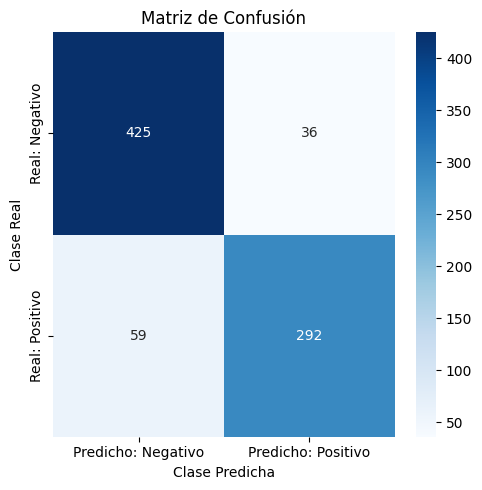

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test_imputed, y_pred_elastic)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Predicho: Negativo', 'Predicho: Positivo'],
            yticklabels=['Real: Negativo', 'Real: Positivo'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

#### Explicabilidad

Tras la buena clasificación de la regresión logística con Elastic Net, procedemos a la explicabilidad. A continuación, veremos qué columnas del dataset contribuyen más a la decisión del modelo.

In [ ]:
coef_df = pd.DataFrame({
    'feature': X_train_imputed.columns,
    'coef': best_model.coef_[0]
}).sort_values(by='coef', key=abs, ascending=False)


In [ ]:
coef_df[abs(coef_df.coef) > 0]

,feature,coef
9,ASIA at Rehab,0.332637
10,Neuro Impairment,-0.254467
50,Sensory PP Left L1,0.230400
28,Motor Score Right L3,0.199726
8,Deep Anal Pressure,0.188550
...,...,...
49,Sensory LT Right S4-5,0.004747
37,Sensory LT Left S1,0.002745
71,"Race_American Indian, Alaska Native",0.001137
89,Injury Etiology Category_Other,0.000718


### Gradient Boosted Machine

**El modelo SÍ acepta valores nulos -> Utilizamos el dataset "normal" (con NaN)**


"Tuning of the eta (range 0.001–1), maximum tree depth (range 2–10), minimum child weight (range 1–25), and subsample (range 0.25–1)"

In [23]:
def objective(trial):
    # Espacio de búsqueda Bayesiano
    params = {
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 1, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 25),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'subsample': trial.suggest_float('subsample', 0.25, 1.0),
        'random_state': 42
    }

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    aucs = []

    for train_idx, val_idx in cv.split(X_train, y_train):

        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]
        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = xgb.XGBClassifier(**params)
        model.fit(X_tr, y_tr)

        y_val_proba = model.predict_proba(X_val)[:, 1]
        aucs.append(roc_auc_score(y_val, y_val_proba))

    return np.mean(aucs)


study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

best_model = xgb.XGBClassifier(**study.best_params)
best_model.fit(X_train, y_train)

[I 2026-05-31 10:39:25,185] A new study created in memory with name: no-name-c030f338-9b20-435f-a231-ec9a919875da


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-05-31 10:39:26,436] Trial 0 finished with value: 0.9338709296012547 and parameters: {'learning_rate': 0.005880522514895962, 'min_child_weight': 9, 'max_depth': 3, 'subsample': 0.4207611706407234}. Best is trial 0 with value: 0.9338709296012547.
[I 2026-05-31 10:39:27,189] Trial 1 finished with value: 0.934380188945941 and parameters: {'learning_rate': 0.46293357438963195, 'min_child_weight': 25, 'max_depth': 5, 'subsample': 0.7034863323357065}. Best is trial 1 with value: 0.934380188945941.
[I 2026-05-31 10:39:28,038] Trial 2 finished with value: 0.9334433686172785 and parameters: {'learning_rate': 0.0031369459085022425, 'min_child_weight': 24, 'max_depth': 7, 'subsample': 0.7771434493445949}. Best is trial 1 with value: 0.934380188945941.
[I 2026-05-31 10:39:28,819] Trial 3 finished with value: 0.9312104292860294 and parameters: {'learning_rate': 0.0010893199475184713, 'min_child_weight': 20, 'max_depth': 4, 'subsample': 0.4857454954177528}. Best is trial 1 with value: 0.93438

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.04078933660661015, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=8, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [24]:
y_pred_xgb = best_model.predict_proba(X_test)[:, 1]

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# AUC-ROC
roc_auc = roc_auc_score(y_test, y_pred_xgb)
print(f"ROC_AUC:           {roc_auc:.3f}  (objetivo: 0.9235)")

# Accuracy
accuracy = accuracy_score(y_test,y_pred_xgb.round())
print(f"Accuracy Score:    {accuracy:.3f}  (objetivo: 0.8586)")

# Recall
recall = recall_score(y_test, y_pred_xgb.round())
print(f"Recall:            {recall:.3f}")

# F1 Score
f1 = f1_score(y_test, y_pred_xgb.round())
print(f"F1 Score:          {f1:.3f}")

# Brier Score
brier = brier_score_loss(y_test, y_pred_xgb)
print(f"Brier Score Loss:  {brier:.3f}")

# intervalo de confianza
low_gbm, up_gbm = bootstrap_ci(y_test.values, y_pred_xgb)
print(f'El intervalo de confianza de XGBoost con roc-auc {roc_auc:.5f} al 95% es [{low_gbm:.5f}, {up_gbm:.5f}]')


# Classification Report
print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test, y_pred_xgb.round()))


MÉTRICAS
ROC_AUC:           0.952  (objetivo: 0.9235)
Accuracy Score:    0.895  (objetivo: 0.8586)
Recall:            0.875
F1 Score:          0.878
Brier Score Loss:  0.081
El intervalo de confianza de XGBoost con roc-auc 0.95157 al 95% es [0.93729, 0.96508]

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

         0.0       0.91      0.91      0.91       461
         1.0       0.88      0.87      0.88       351

    accuracy                           0.90       812
   macro avg       0.89      0.89      0.89       812
weighted avg       0.90      0.90      0.90       812



In [25]:
# análisis especial categorías B y C

X_test_BC = X_test[(X_test['ASIA at Rehab'] == 3.0) | (X_test['ASIA at Rehab'] == 2.0)]
y_test_BC = y_test[X_test_BC.index]

y_pred_BC_xgb = best_model.predict(X_test_BC)
y_proba_BC_xgb = best_model.predict_proba(X_test_BC)[:, 1]

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# C-statistic (AUC-ROC)
roc_auc = roc_auc_score(y_test_BC, y_pred_BC_xgb)
print(f"ROC_AUC:           {roc_auc:.3f}")

# Accuracy
accuracy = accuracy_score(y_test_BC,y_pred_BC_xgb)
print(f"Accuracy Score:    {accuracy:.3f}")

# Recall
recall = recall_score(y_test_BC, y_pred_BC_xgb)
print(f"Recall:            {recall:.3f}")

# F1
f1 = f1_score(y_test_BC, y_pred_BC_xgb)
print(f"F1 Score:          {f1:.3f}")

# Brier Score
brier_score = brier_score_loss(y_test_BC, y_proba_BC_xgb)
print(f"Brier Score:       {brier_score:.3f}")

# intervalo de confianza
low_xgb, up_xgb = bootstrap_ci(y_test_BC.values, y_pred_BC_xgb)
print(f'El intervalo de confianza de XGBoost con roc-auc {roc_auc:.5f} al 95% es [{low_xgb:.5f}, {up_xgb:.5f}]')

print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test_BC, y_pred_BC_xgb))

MÉTRICAS
ROC_AUC:           0.794
Accuracy Score:    0.801
Recall:            0.734
F1 Score:          0.766
Brier Score:       0.141
El intervalo de confianza de XGBoost con roc-auc 0.79398 al 95% es [0.74090, 0.84008]

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

         0.0       0.80      0.85      0.83       137
         1.0       0.80      0.73      0.77       109

    accuracy                           0.80       246
   macro avg       0.80      0.79      0.80       246
weighted avg       0.80      0.80      0.80       246



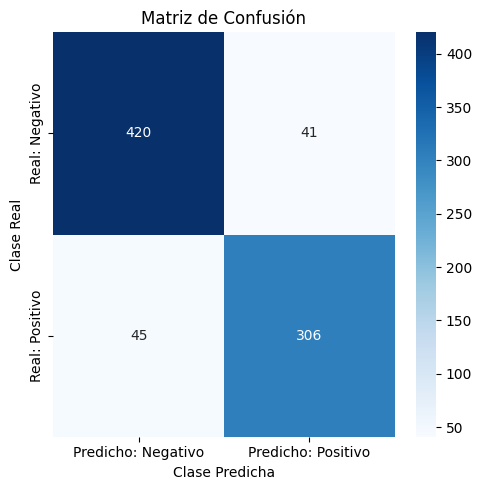

In [ ]:

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb.round())

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Predicho: Negativo', 'Predicho: Positivo'],
            yticklabels=['Real: Negativo', 'Real: Positivo'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

#### Explicabilidad (SHAP)

In [ ]:
# Explainer específico para árboles
explainer = shap.TreeExplainer(best_model)

# shap_values: (n_samples, n_features)
shap_values = explainer.shap_values(X_test)


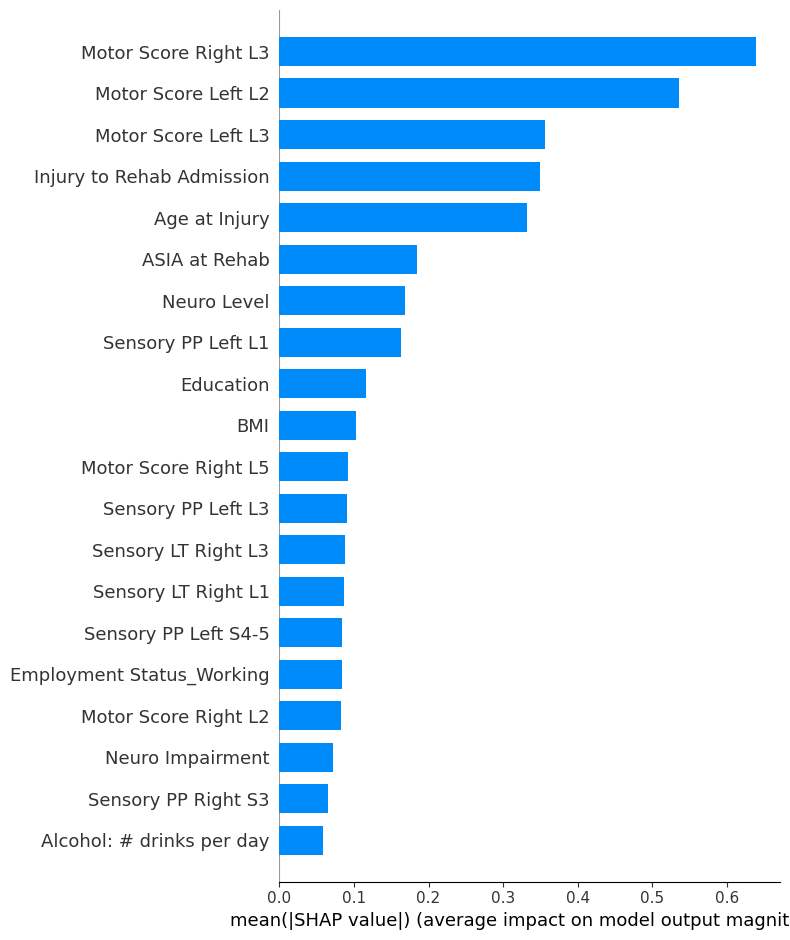

In [ ]:
shap.summary_plot(shap_values, X_test, plot_type="bar")

### ANN

In [27]:
X_train_numpy = X_train_imputed.to_numpy(dtype='float32')
X_test_numpy = X_test_imputed.to_numpy(dtype='float32')
y_train_numpy = y_train_imputed.to_numpy(dtype='float32')
y_test_numpy = y_test_imputed.to_numpy(dtype='float32')

n_features = X_train_numpy.shape[1]


In [ ]:
param_grid = {
    "hidden_nodes": [8, 16, 32, 64, 128, 256],
    "dropout_rate": [0.1, 0.2, 0.3, 0.4],
    "optimizer": ['adam', 'rmsprop'],
    "learning_rate": [0.1, 0.05],
}


# generar todas las combinaciones
all_combinations = list(ParameterGrid(param_grid))
total_combinations = len(all_combinations)

# seleccionar 5% de combinaciones aleatoriamente
n_trials = int(0.05 * total_combinations)
selected_indices = np.random.choice(total_combinations, size=n_trials, replace=False)
selected_combinations = [all_combinations[i] for i in selected_indices]

for params in selected_combinations:

  inputs = Input(shape=(n_features,))

  # Primera capa oculta densa
  x = Dense(params['hidden_nodes'], activation='relu')(inputs)
  x = Dropout(params['dropout_rate'])(x)  # regularización

  # Capa de salida
  outputs = Dense(1, activation='sigmoid')(x)

  # Construir modelo
  model = Model(inputs=inputs, outputs=outputs)

  if params['optimizer'] == 'adam':
    model.compile(optimizer=Adam(learning_rate=params['learning_rate']),
                loss='binary_crossentropy',
                metrics=[AUC(name='auc')])

  if params['optimizer'] == 'rmsprop':
    model.compile(optimizer=RMSprop(learning_rate=params['learning_rate']),
                  loss='binary_crossentropy',
                  metrics=[AUC(name='auc')])

  history = model.fit(
    X_train_numpy, y_train_numpy,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)
  loss, roc_auc = model.evaluate(X_test_numpy, y_test_numpy)
  print("ROC-AUC", roc_auc)


Epoch 1/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - auc: 0.8175 - loss: 5.0577 - val_auc: 0.9123 - val_loss: 0.4990
Epoch 2/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - auc: 0.8378 - loss: 0.5411 - val_auc: 0.5326 - val_loss: 0.6780
Epoch 3/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - auc: 0.7366 - loss: 0.5904 - val_auc: 0.8989 - val_loss: 0.7866
Epoch 4/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - auc: 0.7918 - loss: 0.5294 - val_auc: 0.6365 - val_loss: 0.6607
Epoch 5/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.7581 - loss: 0.5884 - val_auc: 0.6116 - val_loss: 0.7251
Epoch 6/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - auc: 0.7643 - loss: 0.5228 - val_auc: 0.7880 - val_loss: 0.5102
Epoch 7/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - auc: 0.7631 - loss: 0.5372 - val_auc: 0.7469 - val_loss: 0.5862
Epoch 8/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.8217 - loss: 0.4752 - val_auc: 0.3748 - val_loss: 0.9162
Epoch 9/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.7390 - loss:

In [ ]:
print("Mejor combinación (0.9337220788002014):")
print(selected_combinations[1])

Mejor combinación (0.9337220788002014):
{'dropout_rate': 0.2, 'hidden_nodes': 128, 'learning_rate': 0.05, 'optimizer': 'rmsprop'}


In [28]:
# mejor modelo

inputs = Input(shape=(n_features,))

x = Dense(128, activation='relu')(inputs)
x = Dropout(0.2)(x)  # regularización

# Capa de salida
outputs = Dense(1, activation='sigmoid')(x)

# Construir modelo
model = Model(inputs=inputs, outputs=outputs)

model.compile(optimizer=RMSprop(learning_rate=0.05),
              loss='binary_crossentropy',
              metrics=[AUC(name='auc')])

history = model.fit(
    X_train_numpy, y_train_numpy,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)



Epoch 1/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - auc: 0.8596 - loss: 1.6095 - val_auc: 0.9092 - val_loss: 0.6148
Epoch 2/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.8995 - loss: 0.4452 - val_auc: 0.9098 - val_loss: 0.5848
Epoch 3/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - auc: 0.9114 - loss: 0.4203 - val_auc: 0.9109 - val_loss: 0.5889
Epoch 4/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - auc: 0.9032 - loss: 0.4484 - val_auc: 0.9251 - val_loss: 0.3813
Epoch 5/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - auc: 0.9099 - loss: 0.3914 - val_auc: 0.9057 - val_loss: 0.8807
Epoch 6/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - auc: 0.9051 - loss: 0.4257 - val_auc: 0.8726 - val_loss: 0.4438
Epoch 7/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - auc: 0.9087 - loss: 0.4201 - val_auc: 0.8947 - val_loss: 1.1354
Epoch 8/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.9094 - loss: 0.4357 - val_auc: 0.9240 - val_loss: 0.3867
Epoch 9/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.9105 - loss:

In [ ]:
# RESULTADOS

y_pred_proba = model.predict(X_test_numpy, verbose=0).flatten()
y_pred_class = (y_pred_proba >= 0.5).astype(int)

roc_auc = roc_auc_score(y_test_numpy, y_pred_proba)
accuracy = accuracy_score(y_test_numpy, y_pred_class)
recall = recall_score(y_test_numpy, y_pred_class)
f1 = f1_score(y_test_numpy, y_pred_class)
brier = brier_score_loss(y_test_numpy, y_pred_proba)
low_rrnn, up_rrnn = bootstrap_ci(y_test_numpy, y_pred_proba)

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)
print(f"ROC_AUC:           {roc_auc:.3f}  (objetivo: 0.9322)")
print(f"Accuracy Score:    {accuracy:.3f}  (objetivo: 0.8729)")
print(f"Recall:            {recall:.3f}")
print(f"F1 Score:          {f1:.3f}")
print(f"Brier Score Loss:  {brier:.3f}")
print(f'El intervalo de confianza de la RRNN con roc-auc {roc_auc:.5f} al 95% es [{low_rrnn:.5f}, {up_rrnn:.5f}]')



MÉTRICAS
ROC_AUC:           0.946  (objetivo: 0.9322)
Accuracy Score:    0.893  (objetivo: 0.8729)
Recall:            0.895
F1 Score:          0.878
Brier Score Loss:  0.092
El intervalo de confianza de la RRNN con roc-auc 0.94576 al 95% es [0.92956, 0.96076]


In [31]:
# análisis especial categorías B y C


X_test_BC_numpy = X_test_BC_imputed.to_numpy(dtype='float32')
y_test_BC_numpy = y_test_BC_imputed.to_numpy(dtype='float32')

y_pred_BC_proba = model.predict(X_test_BC_numpy, verbose=0).flatten()
y_pred_BC_class = (y_pred_BC_proba >= 0.5).astype(int)

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# C-statistic (AUC-ROC)
roc_auc = roc_auc_score(y_test_BC_numpy, y_pred_BC_class)
print(f"ROC_AUC:           {roc_auc:.3f}")

# Accuracy
accuracy = accuracy_score(y_test_BC_numpy, y_pred_BC_class)
print(f"Accuracy Score:    {accuracy:.3f}")

# Recall
recall = recall_score(y_test_BC_numpy, y_pred_BC_class)
print(f"Recall:            {recall:.3f}")

# F1
f1 = f1_score(y_test_BC_numpy, y_pred_BC_class)
print(f"F1 Score:          {f1:.3f}")

# Brier Score
brier_score = brier_score_loss(y_test_BC_numpy, y_pred_BC_proba)
print(f"Brier Score:       {brier_score:.3f}")

# intervalo de confianza
low_xgb, up_xgb = bootstrap_ci(y_test_BC_numpy, y_pred_BC_class)
print(f'El intervalo de confianza de XGBoost con roc-auc {roc_auc:.5f} al 95% es [{low_xgb:.5f}, {up_xgb:.5f}]')

print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test_BC_numpy, y_pred_BC_class))

MÉTRICAS
ROC_AUC:           0.754
Accuracy Score:    0.760
Recall:            0.697
F1 Score:          0.720
Brier Score:       0.195
El intervalo de confianza de XGBoost con roc-auc 0.75373 al 95% es [0.69816, 0.80474]

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

         0.0       0.77      0.81      0.79       137
         1.0       0.75      0.70      0.72       109

    accuracy                           0.76       246
   macro avg       0.76      0.75      0.76       246
weighted avg       0.76      0.76      0.76       246



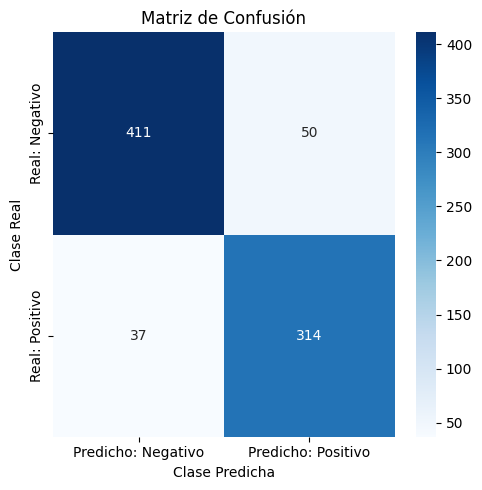

In [ ]:

# Confusion Matrix
cm = confusion_matrix(y_test_numpy, y_pred_class)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Predicho: Negativo', 'Predicho: Positivo'],
            yticklabels=['Real: Negativo', 'Real: Positivo'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

#### Explicabilidad

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
682/682 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
684/684 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
682/682 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
682/682 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
682/682 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
684/684 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
684/684 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
684/684 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
683/683 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
685/685 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
681/681 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
685/685 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
683/683 ━━━━━

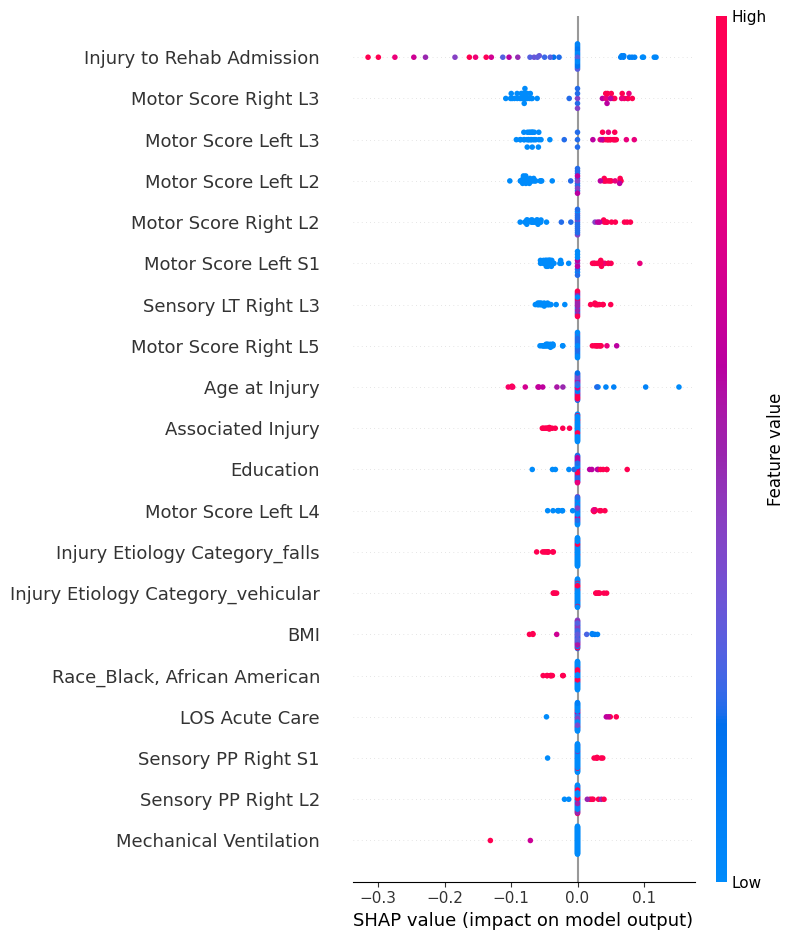

In [ ]:

background = shap.kmeans(X_train_numpy, 10)

def predict_fn(x):
    return model.predict(x).flatten()

# explainer
explainer = shap.KernelExplainer(predict_fn, background)

X_sample = X_test_numpy[:50]
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample, feature_names=X_train.columns.to_list())